# TP Parcial — Localización y Movimiento
### Principios de la Robótica Autónoma · Universidad de San Andrés
**Joaquín Di Cola**

## Objetivo

El objetivo del primer ejercicio es localizar al robot en un mapa conocido mediante un **filtro de partículas** que combina odometría y lecturas LIDAR. A partir de la posición estimada se integra la planificación de caminos con **A\*** y el seguimiento mediante **Pure Pursuit**.

La implementación se probó en Gazebo y RViz, primero por componentes y después mediante navegación autónoma. Se analizaron tres cantidades de partículas, distintas dispersiones iniciales, cambios en el parámetro `sigma` y un recorrido próximo a obstáculos.

Para interpretar las capturas, los colores utilizados en RViz fueron: **verde** para la trayectoria real, **azul** para la odometría, **rojo** para la estimación del filtro y **magenta** para la ruta planificada.

# 1. Filtro de partículas

## 1.1 Entorno de simulación

Se utilizó el escenario de Gazebo y la visualización de RViz para comprobar el mapa, las lecturas del LIDAR y la evolución de las partículas durante el movimiento del robot.

## 1.2 Campo de verosimilitud (*likelihood field*)

El mapa de ocupación indica si cada celda es libre (`0`), ocupada (`100`) o desconocida (`-1`). Para evaluar una lectura LIDAR, se construyó un mapa de verosimilitud que asigna mayor valor a las posiciones cercanas a obstáculos.

Para cada celda se calcula la distancia $d$ al obstáculo más cercano y se aplica:

$$
L(d)=\exp\left(-\frac{d^2}{2\sigma^2}\right).
$$

En `likelihood.py`, `distance_transform_edt` calcula esas distancias sobre la matriz del mapa. La matriz se reconstruye con dimensiones `(height, width)` y se consulta como `[y, x]`. En esta implementación la distancia y `sigma` se expresan **en celdas**.

```python
occupied = occupancy_grid == 100
distance = distance_transform_edt(~occupied)
likelihood = np.exp(-(distance ** 2) / (2.0 * self.sigma ** 2))
likelihood_grid = np.clip(np.round(likelihood * 100), 0, 100).astype(np.int8)
prob_msg.data = likelihood_grid.flatten().tolist()
```

Se conservan el encabezado, la resolución y el origen del `OccupancyGrid` original. El resultado se publica en `/likelihood_map` como valores entre 0 y 100. La publicación se verificó con el mensaje `Published likelihood map` y su visualización en RViz.

![Campo de verosimilitud visualizado en RViz.](graficos/punto1/1_2_likelihood/likelihood.png)

*Figura — Campo de verosimilitud visualizado en RViz.*

### Influencia de `sigma` sobre el campo

El siguiente gráfico permite visualizar cómo cambia la probabilidad con la distancia a un obstáculo.

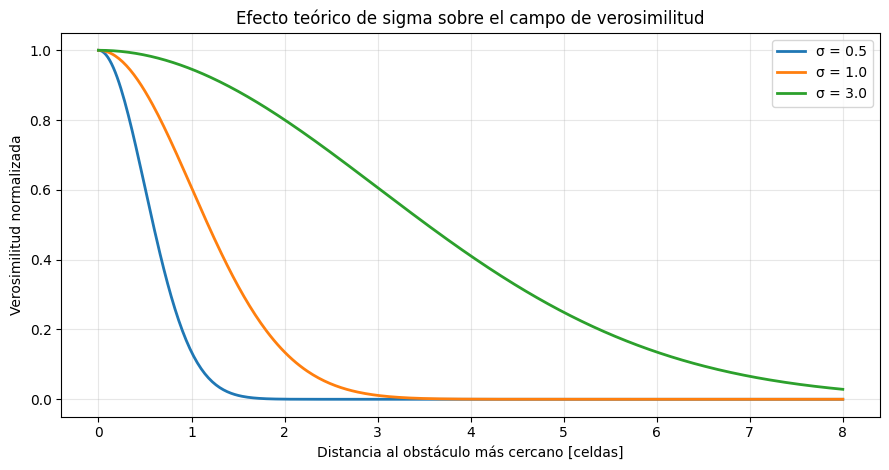

In [1]:
# Curvas del likelihood field para los valores de sigma evaluados.
import numpy as np
import matplotlib.pyplot as plt

distancias_celdas = np.linspace(0.0, 8.0, 400)
valores_sigma = [0.5, 1.0, 3.0]

plt.figure(figsize=(9, 4.8))
for sigma in valores_sigma:
    probabilidad = np.exp(-distancias_celdas**2 / (2.0 * sigma**2))
    plt.plot(distancias_celdas, probabilidad, label=f"σ = {sigma}", linewidth=2)

plt.xlabel("Distancia al obstáculo más cercano [celdas]")
plt.ylabel("Verosimilitud normalizada")
plt.title("Efecto teórico de sigma sobre el campo de verosimilitud")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

Con `sigma=0.5`, los valores altos se concentran cerca del obstáculo; con `sigma=3.0`, la probabilidad disminuye más gradualmente. Este comportamiento se contrastó después con las pruebas en RViz.

## 1.3 Inicialización de partículas

Se agregó una suscripción a `/initialpose`, utilizada por la herramienta **2D Pose Estimate** de RViz. El clic fija la posición inicial y la dirección de la flecha indica la orientación del robot.

La pose inicial se representa mediante $N$ partículas con pequeñas perturbaciones gaussianas:

$$
x_0^{(i)}\sim\mathcal{N}(x_0,\sigma_x^2),\qquad
y_0^{(i)}\sim\mathcal{N}(y_0,\sigma_y^2),\qquad
\theta_0^{(i)}\sim\mathcal{N}(\theta_0,\sigma_\theta^2).
$$

Se asignó a todas las partículas un peso inicial $1/N$ y se normalizaron sus orientaciones al intervalo $[-\pi,\pi)$. La configuración habitual fue **1000 partículas**, con dispersión de **0.20 m** en cada eje y **10°** en orientación.

Las partículas se publican como `PointCloud2` en `/particle_cloud`. Al seleccionar una pose en RViz se observó la nube alrededor del robot y se recibió el mensaje `Inicializadas 1000 partículas`.

![Nube de partículas después de seleccionar la pose inicial.](graficos/punto1/1_3_inicializacion/inicializacion.png)

*Figura — Nube de partículas después de seleccionar la pose inicial.*

## 1.4 Predicción a partir de la odometría

En `odom_callback()` se compara la odometría actual con la anterior para obtener el desplazamiento del robot y su cambio de orientación. El desplazamiento se expresa en el marco local del robot y se aplica a cada partícula utilizando **su propia orientación**.

Para modelar la incertidumbre, se suma ruido gaussiano independiente a los desplazamientos y al giro. La varianza depende de la magnitud del movimiento; los coeficientes utilizados fueron:

```python
self.motion_alpha = np.array([0.05, 0.02, 0.005, 0.05, 0.05, 0.05])
```

La actualización de posición de cada partícula sigue la transformación habitual entre el marco local y el global:

$$
\begin{aligned}
x' &= x + \cos\theta\,\Delta x_\ell - \sin\theta\,\Delta y_\ell,\\
y' &= y + \sin\theta\,\Delta x_\ell + \cos\theta\,\Delta y_\ell.
\end{aligned}
$$

Al desplazar y girar el robot manualmente, la nube acompañó su movimiento con pequeñas diferencias entre partículas. Esto permitió validar visualmente la predicción antes de incorporar el sensado.

![Evolución de la nube de partículas durante el movimiento por odometría.](graficos/punto1/1_4_movimiento/movimiento.png)

*Figura — Evolución de la nube de partículas durante el movimiento por odometría.*

## 1.5 Corrección con LIDAR y remuestreo

La predicción por odometría acumula incertidumbre. Por eso, `scan_callback()` utiliza las mediciones del LIDAR para asignar un peso mayor a las partículas cuyas lecturas son compatibles con el mapa.

Se seleccionan **12 haces válidos** por actualización y se calcula, para cada partícula, dónde terminaría cada uno sobre el mapa. Se considera el desplazamiento del LIDAR de **0.043 m** respecto del robot y su rotación de **180°**. El desplazamiento vertical de **0.110 m** no modifica la proyección bidimensional. Los extremos de los haces se convierten en celdas del mapa, utilizando su origen y resolución, y se consulta la verosimilitud correspondiente.

Para combinar las mediciones sin provocar pérdidas de precisión numérica, se acumulan **logaritmos de probabilidades**. Se utilizó además un suavizado `0.15 + 0.85 * probabilidad`, que evita castigar excesivamente pequeñas diferencias entre el mapa y las lecturas.

Luego se normalizan los pesos y se calcula el número efectivo de partículas:

$$
N_{\mathrm{eff}}=\frac{1}{\sum_{i=1}^{N}w_i^2}.
$$

Cuando $N_{\mathrm{eff}}<N/2$, se realiza **remuestreo sistemático**. Para conservar cierta diversidad se añadió *roughening*: ruido de **0.03 m** en posición y **2°** en orientación después del remuestreo.

En las primeras pruebas, al activar el sensado la nube de partículas quedaba prácticamente invisible por su concentración. Se aisló el problema desactivando temporalmente `scan_callback()` y luego se ajustó la selección de haces, el suavizado de pesos y la dispersión posterior al remuestreo. Tras estos cambios, la nube permaneció visible y acompañó al robot mientras avanzaba y giraba.

### Resultado del seguimiento

En la siguiente captura se observa la nube cerca del robot durante el desplazamiento, junto con las trayectorias de referencia.

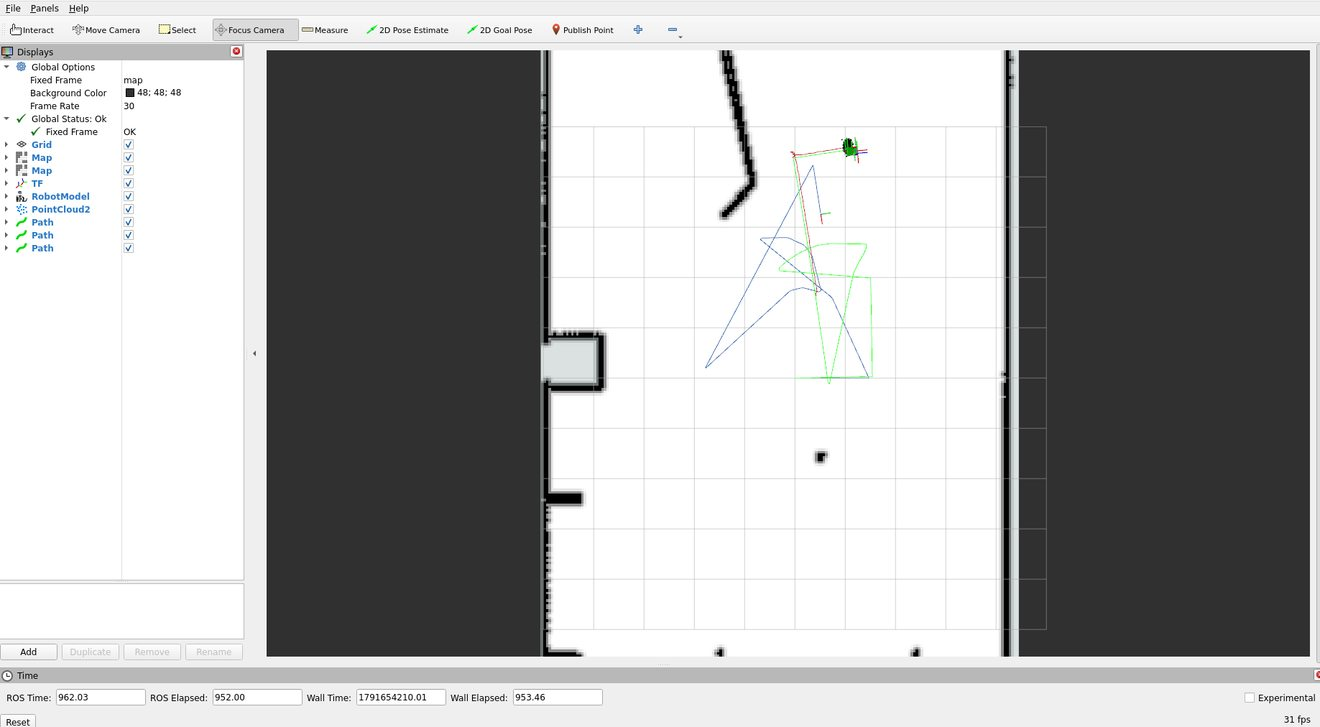

*Figura — Seguimiento del robot después de avanzar y girar: trayectoria filtrada próxima a la real.*

## 1.6 Publicación de la pose estimada

Para utilizar el filtro en navegación se necesita una pose única. Se calculó el **promedio ponderado** de las posiciones y el **promedio circular** de las orientaciones:

$$
\hat x=\sum_i w_i x_i,\qquad
\hat y=\sum_i w_i y_i,\qquad
\hat\theta=\operatorname{atan2}\!\left(\sum_i w_i\sin\theta_i,\sum_i w_i\cos\theta_i\right).
$$

El promedio circular permite combinar correctamente ángulos próximos a $-\pi$ y $\pi$.

Se implementó `publish_particle_pose()` para publicar `nav_msgs/Odometry` en **`/particle_odom`**, con el sistema de referencia `map`. La pose se actualiza después del procesamiento válido del LIDAR y también al inicializar el filtro. En paralelo se publica `/particle_robot_path`, que muestra la **trayectoria roja**. Al reinicializar las partículas se limpia esa trayectoria.

La publicación se verificó mediante `ros2 topic echo /particle_odom --once`. En las pruebas, la trayectoria roja siguió de cerca la verde, mientras que la azul mostró el error acumulado de odometría.

![Trayectoria estimada por el filtro de partículas y recorridos de referencia.](graficos/punto1/1_6_pose_estimada/pose_estimada.png)

*Figura — Trayectoria estimada por el filtro de partículas y recorridos de referencia.*

## 1.7 Navegación con A* y Pure Pursuit

Se incorporaron los paquetes `path_planning` y `path_following` del TP2 al proyecto. En ambos se cambió la suscripción a `/calc_odom` por **`/particle_odom`**, para calcular y seguir caminos utilizando la posición estimada por el filtro.

El planificador recibe el mapa (`/map`), la posición estimada (`/particle_odom`) y la meta seleccionada en RViz (`/goal_pose`). A partir de ellos publica el camino en **`/plan`**. Pure Pursuit utiliza ese camino y la misma posición estimada para enviar velocidades al robot mediante **`/cmd_vel`**.

Los paquetes compilaron correctamente. En la primera prueba se generó una ruta de **31 puntos** y el robot la siguió hasta el destino, donde se detuvo. La integración se visualizó en RViz con el camino magenta y las trayectorias verde, azul y roja.

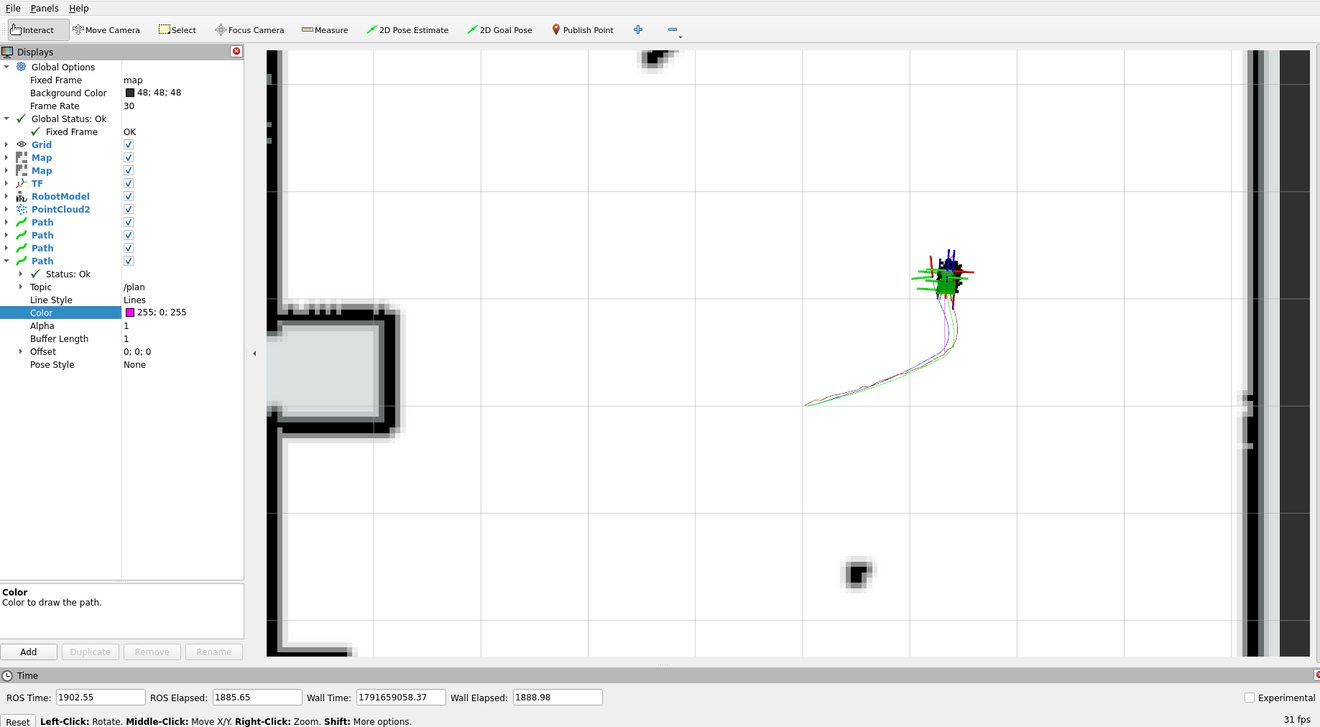

*Figura — Primera integración exitosa: trayectorias real, odométrica, estimada y camino planificado en RViz.*

### Planificación y seguimiento

El planificador utiliza **A\*** con ocho vecinos por celda, costo de $1$ para movimientos ortogonales y $\sqrt{2}$ para diagonales. La heurística es la distancia euclídea al objetivo. Para evitar atravesar esquinas, un movimiento diagonal solo se permite cuando también están libres las celdas adyacentes.

El camino se transforma de coordenadas de grilla a metros y se publica como `nav_msgs/Path`.

Pure Pursuit busca un punto anticipado (*lookahead*) sobre el camino y calcula la velocidad angular mediante:

$$
\kappa=\frac{2y_\ell}{L^2},\qquad \omega=v\kappa.
$$

Se utilizaron **0.30 m** de lookahead, **0.08 m/s** de velocidad lineal y **0.25 m** de tolerancia de llegada. Cuando el robot alcanza el destino, el controlador publica velocidad cero.

### Experimento: cantidad de partículas

Se repitió una navegación corta con **500, 1000 y 2000 partículas**, manteniendo la configuración del filtro y cambiando el argumento `num_particles` del lanzamiento. En las tres pruebas se observó un seguimiento coherente del camino y una nube próxima a la posición del robot. La prueba de 1000 partículas incluyó la llegada y detención en la meta.

Las metas elegidas fueron similares, aunque no exactamente iguales. Por eso, las diferencias en la cantidad de puntos de `/plan` corresponden a rutas distintas y no permiten comparar precisión. El costo del sensado aumenta con el número de partículas, pero no se midieron tiempos de ejecución.

La siguiente celda reúne las coordenadas y los resultados registrados en los logs.

**Resultados de las tres ejecuciones**

In [2]:
# Coordenadas de los objetivos y resultados registrados en ROS 2.
import pandas as pd

pruebas_particulas = pd.DataFrame([
    {"particulas": 500, "meta_x_m": 1.76006, "meta_y_m": 0.884837,
     "puntos_plan": 36, "resultado_observado": "Seguimiento visible"},
    {"particulas": 1000, "meta_x_m": 1.52957, "meta_y_m": 0.589023,
     "puntos_plan": 31, "resultado_observado": "Llegó y se detuvo"},
    {"particulas": 2000, "meta_x_m": 1.88858, "meta_y_m": 0.884837,
     "puntos_plan": 38, "resultado_observado": "Seguimiento visible"},
])
pruebas_particulas

,particulas,meta_x_m,meta_y_m,puntos_plan,resultado_observado
0,500,1.76006,0.884837,36,Seguimiento visible
1,1000,1.52957,0.589023,31,Llegó y se detuvo
2,2000,1.88858,0.884837,38,Seguimiento visible


### Experimento: dispersión inicial

Se comparó la inicialización habitual de **0.20 m y 10°** con otra más dispersa de **0.50 m y 25°**, manteniendo 1000 partículas y el robot quieto.

Con la segunda configuración, las partículas aparecieron distribuidas en una región más amplia y luego se concentraron alrededor del robot al recibir mediciones LIDAR, como muestran las dos capturas.

Una dispersión pequeña facilita concentrar las hipótesis, pero puede dejar fuera la posición real si la inicialización es incorrecta. Una dispersión grande cubre más posiciones posibles, aunque para la misma cantidad de partículas reduce la densidad de hipótesis en cada región. Esto explica por qué la incertidumbre inicial debe ajustarse según la información disponible sobre la pose.

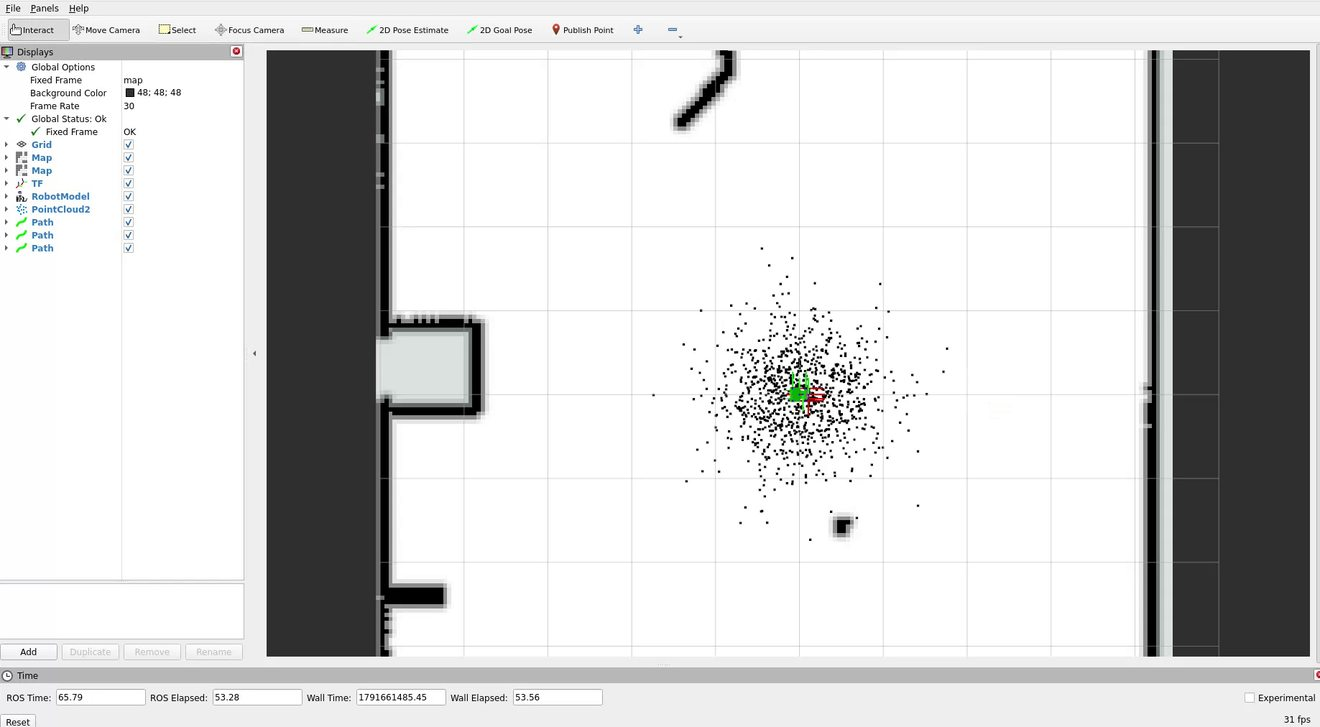

*Figura — Prueba con dispersión inicial de 0.50 m y 25°: partículas al inicio.*

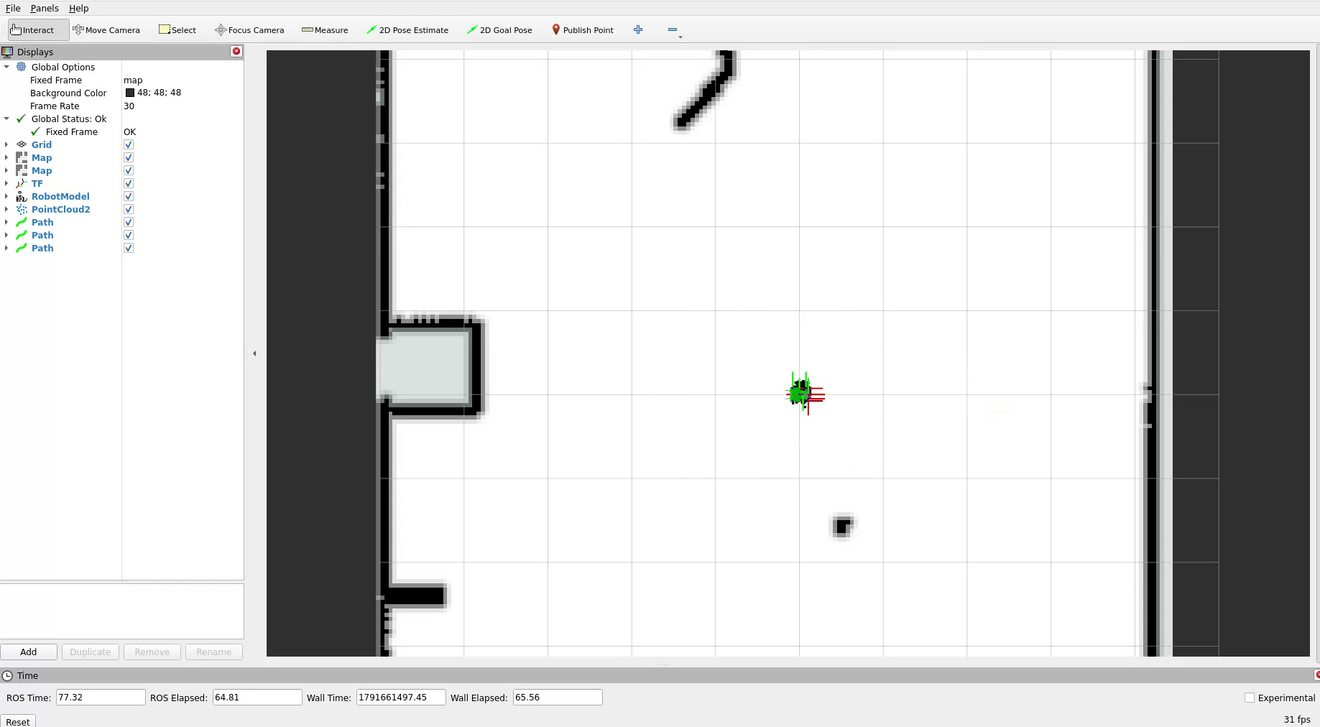

*Figura — Misma prueba, después de varias lecturas LIDAR: nube más concentrada.*

### Experimento: parámetro `sigma`

Se compararon dos ejecuciones con 1000 partículas y el robot quieto:

```bash
ros2 launch tp_parcial particle_filter.launch.py num_particles:=1000 sigma:=3.0
ros2 launch tp_parcial particle_filter.launch.py num_particles:=1000 sigma:=0.5
```

Con **`sigma=0.5`**, el likelihood field asigna valores altos solamente cerca de los obstáculos, lo que hace más estricta la comparación con el LIDAR. Con **`sigma=3.0`**, el campo es más amplio y tolera mayores diferencias espaciales.

En las dos pruebas la nube se concentró rápidamente alrededor del robot y permaneció estable mientras estaba quieto. Visualmente no apareció una diferencia suficiente para determinar qué valor ofrece mejor precisión; para eso haría falta comparar el error de posición con una referencia en un mismo recorrido.

**Sigma = 3.0**

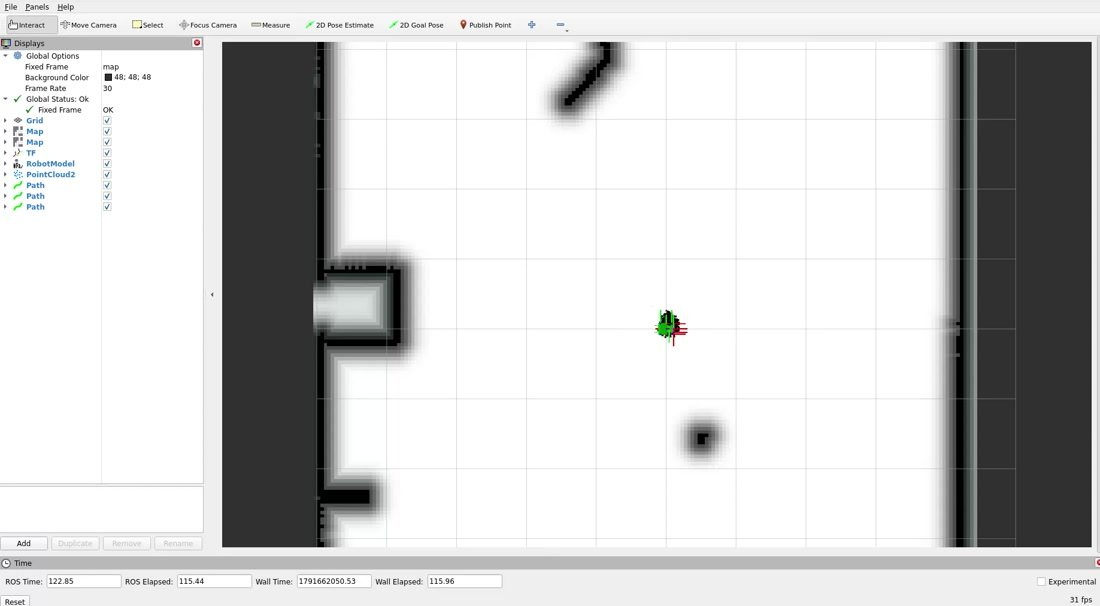

*Figura — Campo con sigma=3.0: nube recién inicializada.*

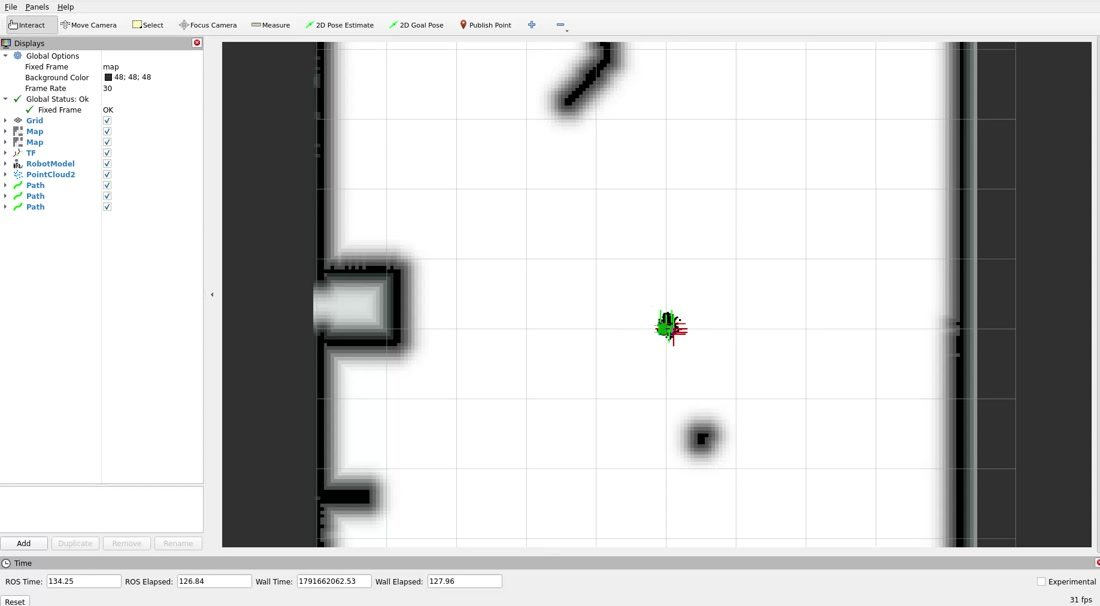

*Figura — Campo con sigma=3.0: nube después de recibir sensado.*

**Sigma = 0.5**

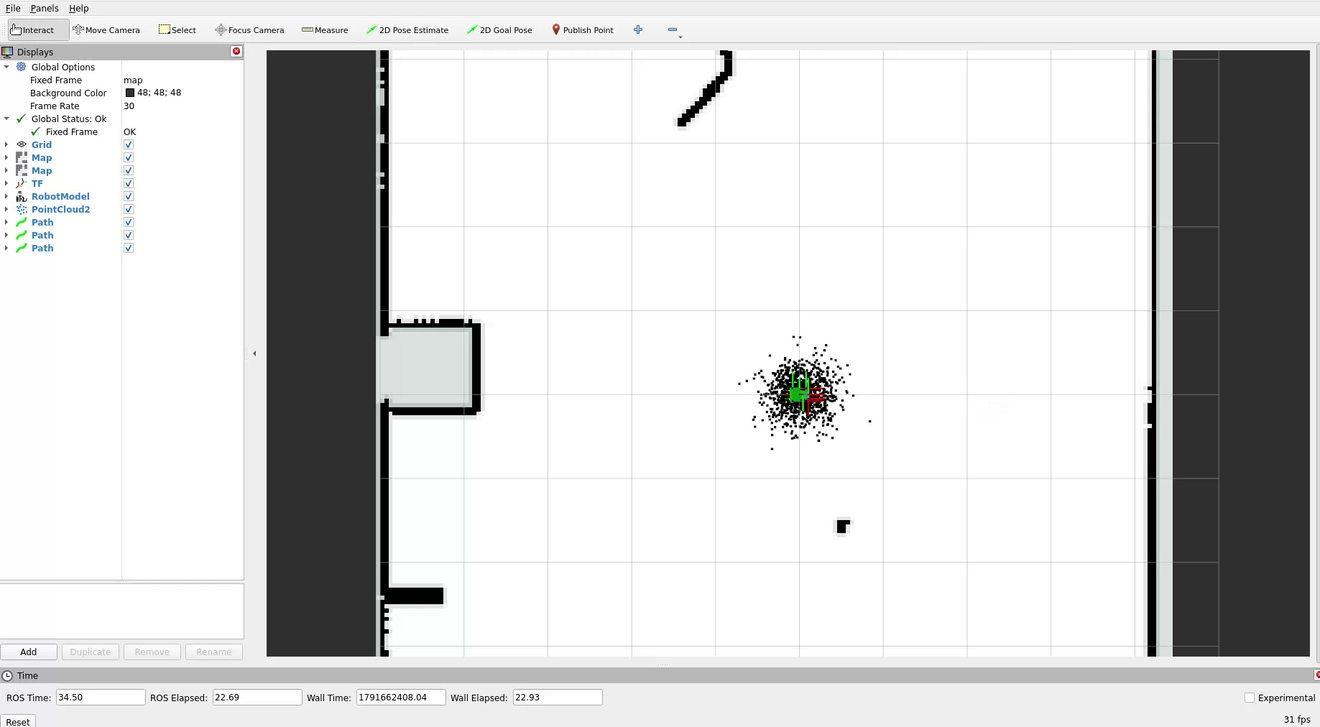

*Figura — Campo con sigma=0.5: nube recién inicializada.*

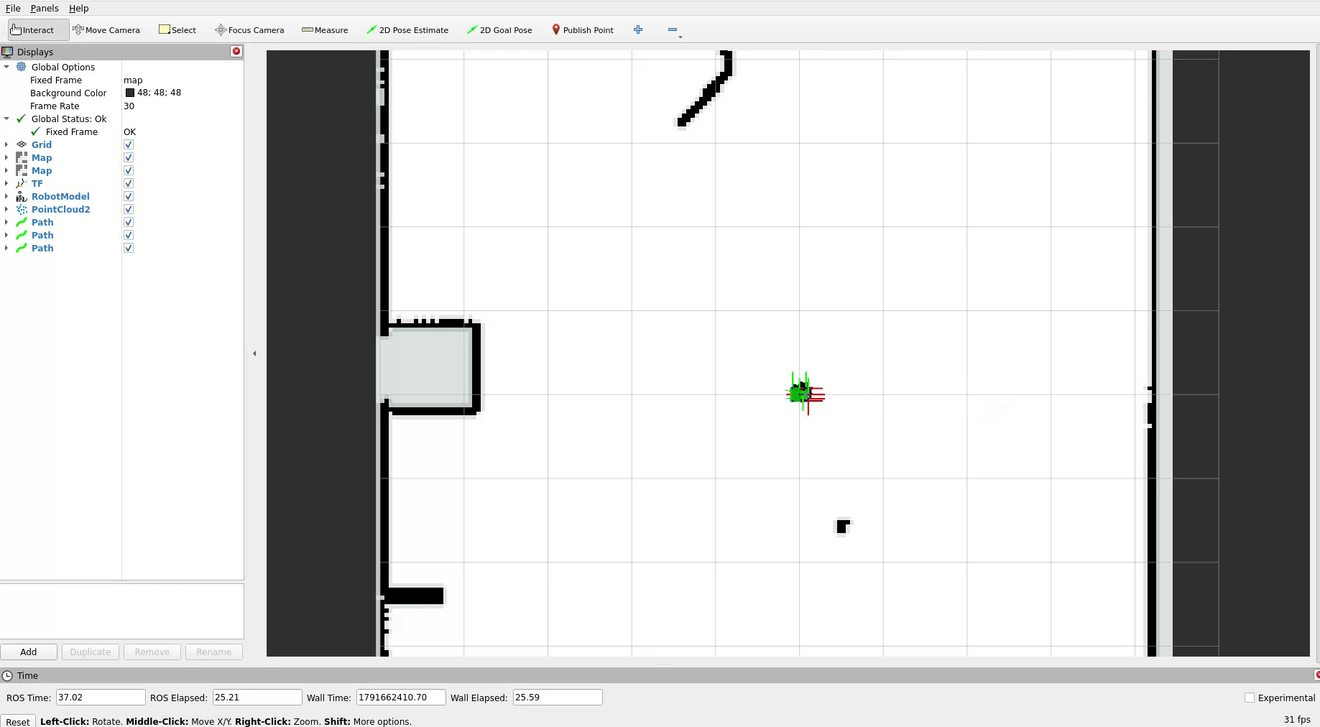

*Figura — Campo con sigma=0.5: nube después de recibir sensado.*

### Navegación cerca de obstáculos

El planificador original distinguía entre celdas libres y ocupadas, pero no contemplaba un margen para el tamaño del robot. Se incorporó **inflación de obstáculos** con un radio de prueba de **0.20 m**.

En `path_planner_node.py` se consideran obstáculos las celdas con ocupación mayor o igual a 50 y las desconocidas. Con `distance_transform_edt` se calcula la distancia hasta el obstáculo más cercano en metros. A* solo utiliza las celdas que cumplen:

$$
d(c)\geq 0.20\ \mathrm{m}.
$$

Con esta modificación se obtuvo una ruta que pasa por encima del saliente de la pared izquierda, manteniendo una separación visible. La inflación se calculó directamente a partir del mapa de ocupación; no se utilizó `/likelihood_map` como costo del planificador. Ese campo podría aprovecharse más adelante para preferir caminos alejados de paredes, además del margen mínimo implementado.

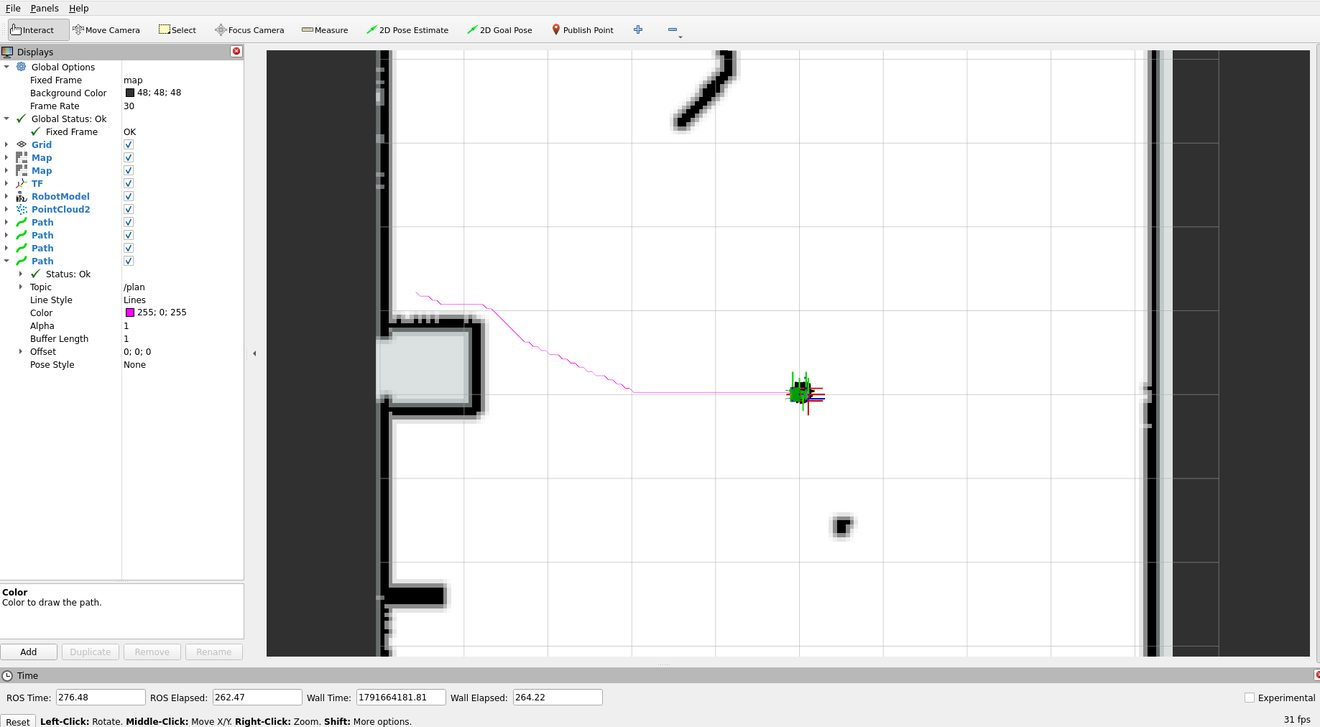

*Figura — A* con inflación de 0.20 m: ruta magenta que rodea el saliente de la pared.*

### Problema detectado: el robot avanzaba cuando debía girar

En la primera prueba con esa ruta, el robot estaba mirando a la derecha y debía desplazarse hacia la izquierda. Sin embargo, avanzó en su orientación original y chocó contra la pared derecha.

El controlador original calculaba la curvatura como $\kappa=2y_\ell/L^2$. Si el punto perseguido queda prácticamente detrás del robot, $y_\ell$ se aproxima a cero y la velocidad angular también, aunque sea necesario un giro grande. Eso explica el comportamiento observado.

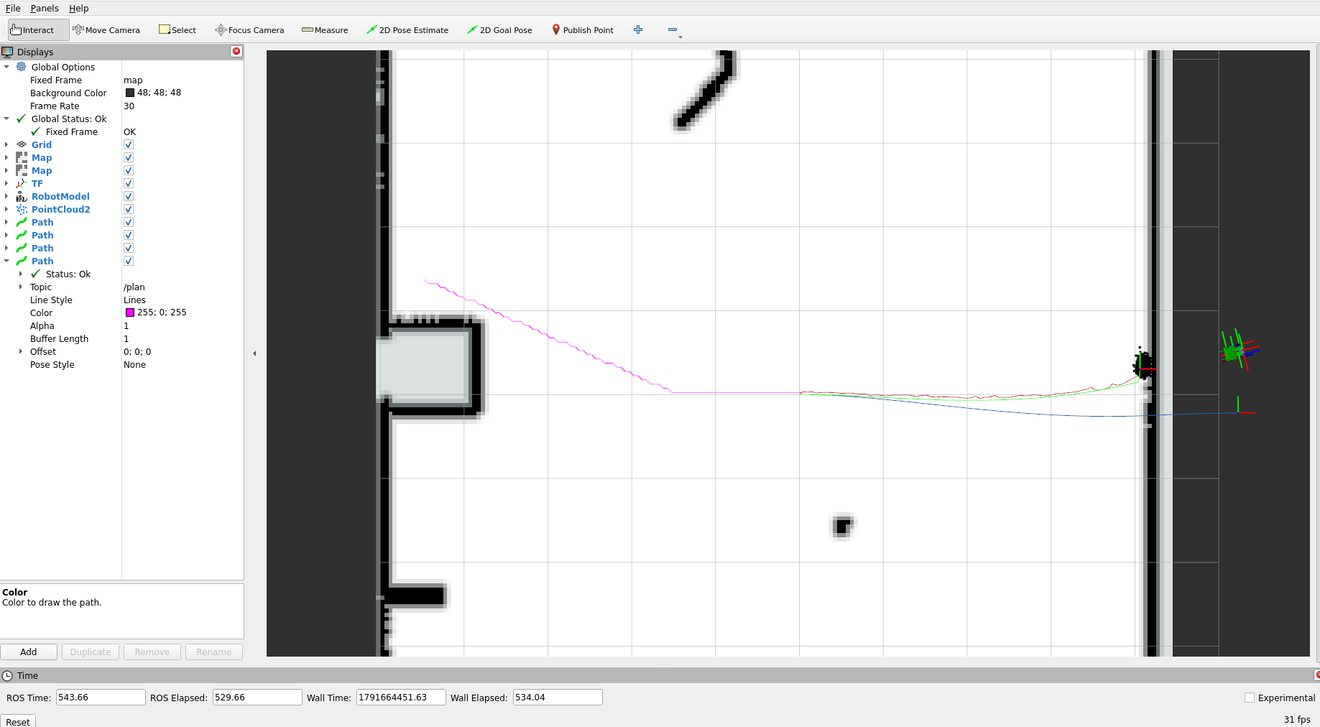

*Figura — Ensayo fallido antes de la corrección: el robot avanza hacia la pared derecha, alejándose de la ruta magenta.*

### Corrección de Pure Pursuit

Se agregó una **alineación angular previa** en `control_loop()`. Se calcula la diferencia entre la orientación del robot y la dirección al punto de lookahead. Si supera **30°**, se ordena velocidad lineal cero y un giro proporcional, limitado a **0.5 rad/s**. Cuando el robot queda orientado hacia el camino, Pure Pursuit vuelve a calcular normalmente las velocidades.

En la nueva prueba el robot giró primero sobre su eje y luego avanzó hacia la izquierda siguiendo el recorrido planificado. En el video llegó a la zona del objetivo sin que se observaran colisiones. Las capturas muestran el giro inicial y el resultado del seguimiento.

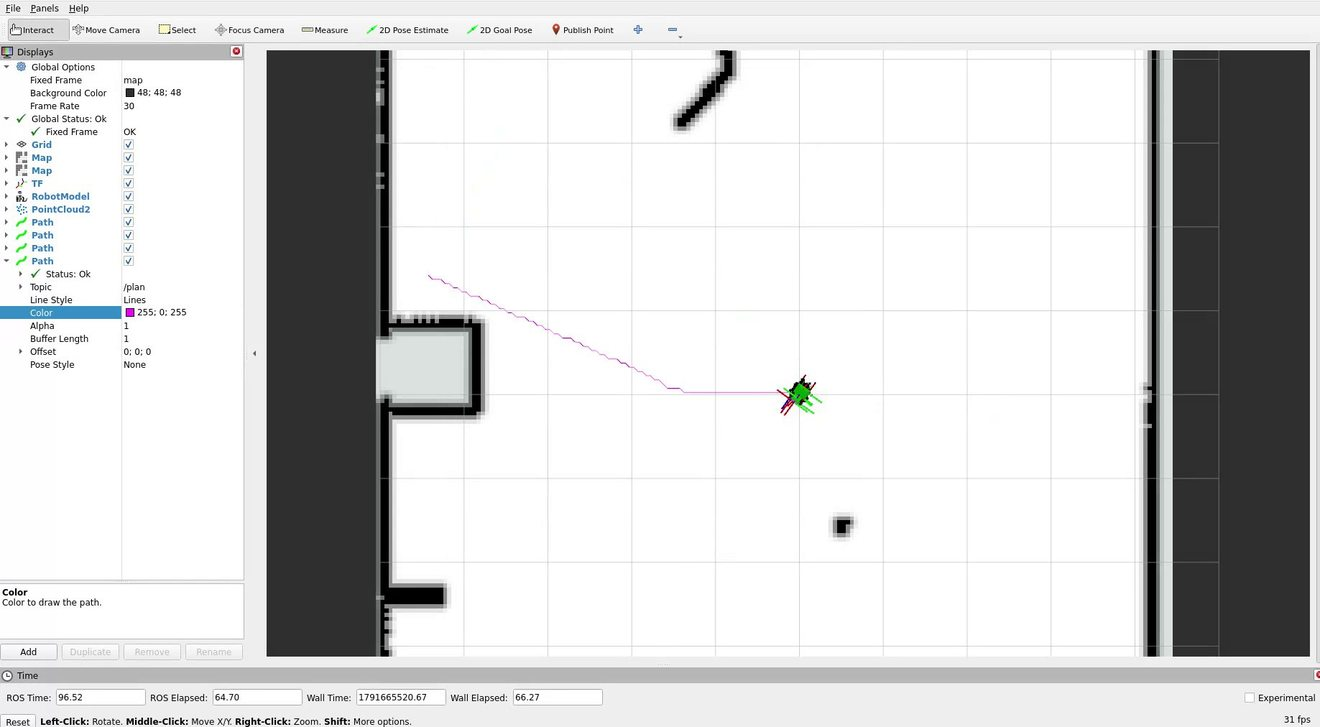

*Figura — Tras la modificación de Pure Pursuit: giro previo para orientarse hacia la ruta.*

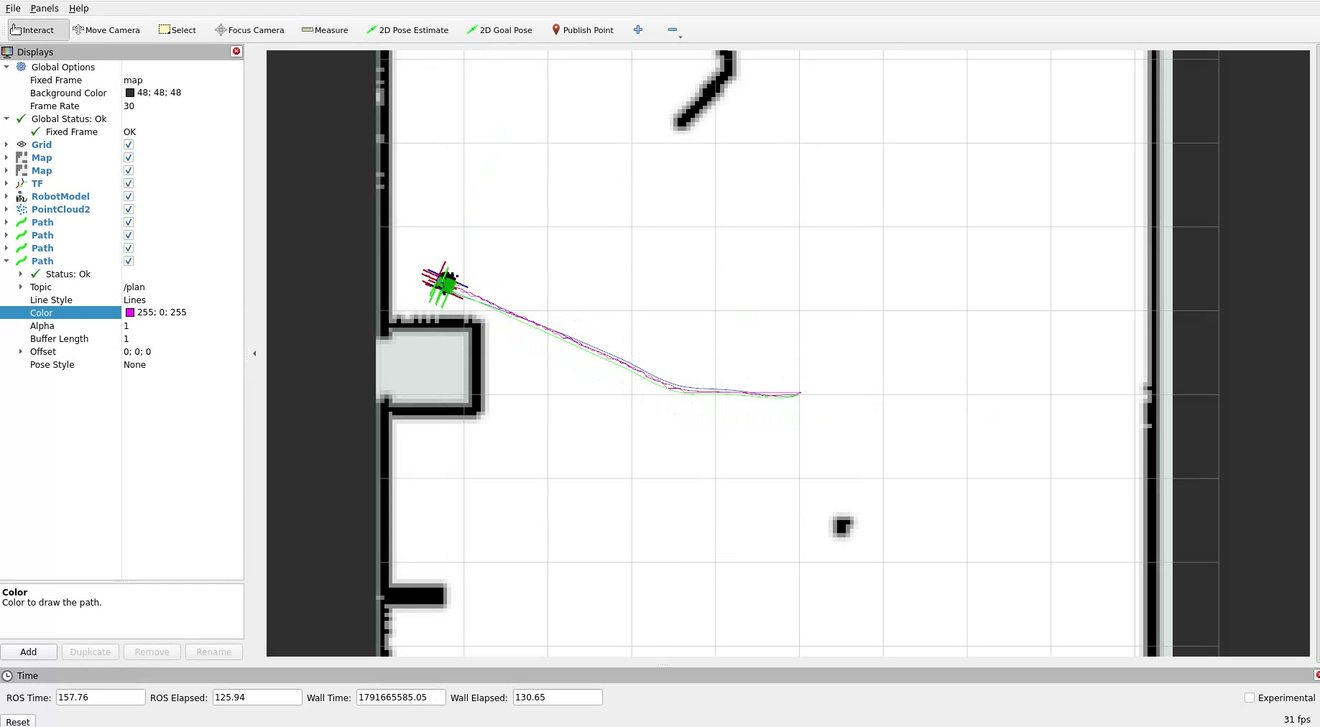

*Figura — Resultado del recorrido tras corregir el giro, utilizando planificación con obstáculos inflados.*

## Conclusiones del punto 1

Se implementó un filtro de partículas que combina odometría y LIDAR para estimar la posición del robot. La estimación publicada en `/particle_odom` permitió reutilizar A* y Pure Pursuit para navegar de manera autónoma.

Las pruebas con **500, 1000 y 2000 partículas** mostraron seguimiento visualmente correcto. También se observó cómo una mayor dispersión inicial se reduce con el sensado y cómo el parámetro `sigma` modifica la extensión del likelihood field. Estas observaciones describen el comportamiento del filtro; no se midieron errores numéricos ni tiempos de cómputo.

La prueba de navegación cerca de una pared permitió mejorar el sistema en dos aspectos: se incorporó un margen de seguridad de **0.20 m** en la planificación y se corrigió el comportamiento de Pure Pursuit cuando debía comenzar con un giro pronunciado. Tras los cambios, el robot siguió la ruta sin una colisión visible.

La configuración final utilizada fue de **1000 partículas**, dispersión inicial de **0.20 m y 10°**, `sigma=1.0` y control de alineación angular previo al seguimiento.

## Ejecución de la navegación integrada

Los cuatro componentes se iniciaron en terminales independientes del contenedor ROS 2:

```bash
ros2 launch custom_map cafe.launch.py rviz:=False
ros2 launch tp_parcial particle_filter.launch.py num_particles:=1000 sigma:=1.0
ros2 run path_planning path_planner
ros2 run path_following pure_pursuit_node
```

En RViz se usó **2D Pose Estimate** para inicializar la posición y **2D Goal Pose** para indicar el destino. Para comprobar la publicación de la estimación se utilizó:

```bash
ros2 topic echo /particle_odom --once
```

Durante la navegación autónoma se mantuvo desactivado `teleop_twist_keyboard` para evitar comandos simultáneos sobre `/cmd_vel`.

# 2. EKF — Localización mediante landmarks

En esta etapa se implementó un filtro de Kalman extendido (EKF) para estimar
la pose bidimensional del robot mediante predicción por odometría y corrección
con referencias conocidas del mapa.

El estado considerado es:

$$
\boldsymbol{\mu}_t =
\begin{bmatrix}x_t & y_t & \theta_t\end{bmatrix}^{T}.
$$

El filtro mantiene una estimación de pose y su matriz de covarianza
$\Sigma_t\in\mathbb{R}^{3\times3}$.

## 2.1. Simulación y observación de landmarks

Se utilizó el escenario del café con landmarks de posición conocida.
El nodo de características publica `/landmarks`, mientras que el observador
publica `/observed_landmarks` en el sistema de referencia del robot.

Cada observación representa una posición relativa al robot. Las entradas
con coordenadas $(0,0)$ indican que la referencia no fue detectada.

El EKF recibe el conjunto de landmarks del mapa y utiliza únicamente las
observaciones válidas para intentar corregir su estimación.

![Mapa del café con las referencias utilizadas para la localización.](graficos/punto2/2_1_mapa_landmarks.png)

*Mapa del café con las referencias utilizadas para la localización..*

## 2.2. Inicialización y predicción

La pose inicial se especifica mediante `/initialpose`. En la configuración
de referencia se adoptaron desviaciones estándar de 0,50 m en posición y
10° en orientación:

$$
\Sigma_0 =
\operatorname{diag}
\left(0.5^2,\ 0.5^2,\ (10\pi/180)^2\right).
$$

La predicción utiliza los incrementos de odometría y una aproximación
lineal local del modelo de movimiento:

$$
\overline{\boldsymbol{\mu}}_t =
f(\boldsymbol{\mu}_{t-1},\mathbf{u}_t),
$$

$$
\overline{\Sigma}_t =
G_t\Sigma_{t-1}G_t^T+Q.
$$

$G_t$ es el jacobiano del modelo de movimiento y $Q$ representa
la incertidumbre incorporada durante la predicción.

En la configuración original se utilizó:

$$
Q=\operatorname{diag}(0.02,\ 0.02,\ 0.02).
$$

La estimación se publica en `/pose_with_covariance`, y la trayectoria
estimada en `/ekf_robot_path`.

![Inicialización de la pose estimada y su incertidumbre.](graficos/punto2/2_2_pose_inicial.png)

*Inicialización de la pose estimada y su incertidumbre..*

![Evolución de la incertidumbre durante la predicción.](graficos/punto2/2_2_prediccion_covarianza.png)

*Evolución de la incertidumbre durante la predicción..*

## 2.3. Corrección con landmarks

El modelo de observación describe el rango y la dirección de un landmark
$(l_x,l_y)$ desde la estimación del robot $(x,y,\theta)$.

Con $\Delta x=l_x-x$, $\Delta y=l_y-y$ y
$q=\Delta x^2+\Delta y^2$:

$$
h(\boldsymbol{\mu},l)=
\begin{bmatrix}
\sqrt{q}\\
\operatorname{atan2}(\Delta y,\Delta x)-\theta
\end{bmatrix}.
$$

El jacobiano de la observación es:

$$
H_t=
\begin{bmatrix}
-\Delta x/\sqrt{q} & -\Delta y/\sqrt{q} & 0\\
\Delta y/q & -\Delta x/q & -1
\end{bmatrix}.
$$

Se consideraron desviaciones estándar de medición de 0,06 m
para rango y 0,07 rad para dirección.

Para cada asociación aceptada se calcula la innovación,
normalizando la diferencia angular al intervalo $[-\pi,\pi]$:

$$
S_t=H_t\overline{\Sigma}_tH_t^T+R,
\qquad
K_t=\overline{\Sigma}_tH_t^TS_t^{-1},
$$

$$
\boldsymbol{\mu}_t=
\overline{\boldsymbol{\mu}}_t+
K_t\left(\mathbf{z}_t-h(\overline{\boldsymbol{\mu}}_t,l)\right).
$$

La covarianza se actualiza a partir de la ganancia de Kalman.
La asociación de landmarks permite descartar observaciones
que no resultan compatibles con la estimación predicha.

Con las observaciones válidas se comprobó una reducción pronunciada
de la covarianza y una corrección de la trayectoria.

![Corrección de la pose mediante observaciones de landmarks.](graficos/punto2/2_3_correccion_landmarks.png)

*Corrección de la pose mediante observaciones de landmarks..*

![Comparación visual de la incertidumbre antes y después de la corrección.](graficos/punto2/2_3_comparacion_covarianzas.png)

*Comparación visual de la incertidumbre antes y después de la corrección..*

![Estimación del EKF durante el desplazamiento del robot.](graficos/punto2/2_3_ekf_en_movimiento.png)

*Estimación del EKF durante el desplazamiento del robot..*

## 2.4. Planificación y seguimiento con la pose filtrada

Se adaptaron los nodos de A* y Pure Pursuit para seleccionar la fuente
de localización mediante el parámetro `localization_source`.

- `particles`: utiliza `/particle_odom`.
- `ekf`: utiliza `/pose_with_covariance`.

La planificación conserva el margen de seguridad de 0,20 m alrededor
de los obstáculos. El seguimiento utiliza el control Pure Pursuit con
un giro previo sobre el lugar cuando el objetivo de seguimiento queda
fuera de un rango angular de aproximadamente 30°.

En la prueba integrada, A* publicó una trayectoria de 93 puntos y
el robot llegó al destino utilizando la pose estimada por el EKF.

![Navegación autónoma integrando EKF, A* y Pure Pursuit.](graficos/punto2/2_4_navegacion_ekf_exitosa.png)

*Navegación autónoma integrando EKF, A* y Pure Pursuit..*

### 2.4.1. Sensibilidad a la covarianza inicial

Se compararon tres desviaciones estándar iniciales de posición y orientación,
manteniendo el escenario con abundantes landmarks.

| Configuración | Desvío XY | Desvío angular | Varianza X final | Varianza Y final | Varianza angular final |
|---|---:|---:|---:|---:|---:|
| Pequeña | 0,10 m | 3° | 1,477e-5 | 2,542e-6 | 2,200e-6 |
| Original | 0,50 m | 10° | 1,974e-5 | 3,318e-6 | 2,788e-6 |
| Grande | 1,00 m | 25° | 1,522e-5 | 2,604e-6 | 2,189e-6 |

En las tres configuraciones la covarianza descendió hasta valores muy
pequeños. La abundancia de observaciones hizo que las estimaciones
convergieran rápidamente, aunque las mediciones corresponden a
instantes diferentes y no constituyen ensayos estadísticamente repetidos.

Para evaluar la recuperación ante una inicialización incorrecta, se
introdujo deliberadamente un error de 0,30 m en X. El robot permaneció
cerca del origen real.

| Configuración | Estimación final | Error final aproximado |
|---|---|---:|
| 0,10 m / 3° | (-0,00356; 0,00304) m | 4,7 mm |
| 1,00 m / 25° | (0,01337; 0,01013) m | 16,8 mm |

Ambos ensayos recuperaron una pose cercana al origen. En este escenario,
una covarianza pequeña no impidió la corrección del error inicial.
La diferencia entre resultados no permite afirmar que una de las
configuraciones sea universalmente superior.

### 2.4.2. Sensibilidad a la matriz Q

Se hicieron tres recorridos rectos cortos, con la misma covarianza
inicial y diferentes valores de la diagonal de Q.

| Diagonal de Q | Desplazamiento aprox. | Var(X) final | Var(Y) final | Var(θ) final | Error de posición |
|---|---:|---:|---:|---:|---:|
| 0,002 | 0,62 m | 7,715e-5 | 9,955e-6 | 8,817e-6 | 3,74 mm |
| 0,020 | 0,61 m | 2,538e-5 | 3,031e-6 | 2,735e-6 | 6,79 mm |
| 0,200 | 0,70 m | 5,119e-5 | 6,027e-6 | 5,205e-6 | 2,72 mm |

El error se calculó como la distancia euclidiana entre la posición
estimada y `/ground_truth/odom`, una vez detenido el robot.

Los tres ensayos produjeron errores inferiores a 1 cm. No se observa
una relación monótona entre Q, covarianza final y error, ya que las
correcciones con landmarks y las condiciones de cada recorrido
también influyen. Las distancias fueron similares, pero no idénticas.

In [ ]:
from math import hypot

pruebas = {
    0.002: ((0.6191808954, 0.0056242121),
            (0.6161060166, 0.0077500657)),
    0.020: ((0.6152689366, -0.0114372676),
            (0.6101664127, -0.0069499819)),
    0.200: ((0.7029721377, 0.0254842160),
            (0.7002962987, 0.0249996190)),
}

print("Q       | Error de posición (mm)")
print("-" * 35)
for q, (ekf, real) in pruebas.items():
    error_mm = 1000 * hypot(ekf[0]-real[0], ekf[1]-real[1])
    print(f"{q:7.3f} | {error_mm:9.3f}")

### 2.4.3. Influencia del campo de visión (FOV)

El campo de visión del observador se comparó en dos configuraciones.

| Condición | Landmarks observados | Landmarks utilizados |
|---|---:|---:|
| FOV 60°, orientación inicial | 0 | 0 |
| FOV 60°, después de girar | 6 | 1–2 |
| FOV 360°, orientación inicial | 21 | 18–21 |

Con 60° el robot quedó inicialmente sin referencias. Al girar,
encontró nuevas observaciones, aunque la asociación aceptó solamente
una parte de ellas. Con 360°, se dispuso de muchas más oportunidades
de corrección sin necesidad de rotación.

Un FOV más amplio facilita la disponibilidad de observaciones, pero
no garantiza que todas las asociaciones sean correctas.

### 2.4.4. Región con pocos landmarks utilizables

El robot se desplazó hacia el sector cercano a la barra y la pared externa.
Durante el recorrido, la cantidad de referencias observadas descendió de
aproximadamente 21 a 3. Finalmente, el filtro registró repetidamente:

`Landmarks observados: 3; asociados y usados: 0`.

La matriz de covarianza alcanzó aproximadamente:

$$
\Sigma =
\begin{bmatrix}
0.92497 & -0.38580 & -0.13741\\
-0.38580 & 0.16513 & 0.05753\\
-0.13741 & 0.05753 & 0.02530
\end{bmatrix}.
$$

La posición real medida fue aproximadamente
$(-2.3990,\ 4.4375)$ m, mientras que el EKF estimó
$(-2.4225,\ 3.8800)$ m.

El error euclidiano resultó:

$$e \approx 0.558\ \mathrm{m}.$$

Esta experiencia evidencia que no basta con detectar landmarks:
el filtro debe poder asociarlos correctamente. Sin observaciones
aceptadas, la incertidumbre de la predicción se acumuló y la
estimación se alejó de la pose real.

![Separación entre la trayectoria estimada y la real en una zona con pocas asociaciones válidas.](graficos/punto2/2_4_zona_pocos_landmarks.png)

*Separación entre la trayectoria estimada y la real en una zona con pocas asociaciones válidas..*

# 3. Evaluación con rosbag del robot real

Se reprodujo la grabación provista para el parcial utilizando el
mapa real y el filtro de partículas desarrollado en el punto 1.

La grabación contiene 23.986 mensajes y una duración de 163,858 s,
incluyendo 1.633 mensajes de `/odom` y 1.188 mensajes de `/scan`.

Se verificó la suscripción del filtro a `/odom` y `/scan`, este
último con un perfil QoS compatible con `Best Effort`.

Se utilizaron 1.000 partículas. En la segunda ejecución, la pose se
inicializó cuando habían transcurrido aproximadamente tres segundos
del rosbag. Se registraron 1.171 estimaciones publicadas en
`/particle_odom`.

## 3.1. Resultado del recorrido

Las posiciones del filtro registradas fueron:

| Variable | Valor |
|---|---|
| Pose inicial (XY) | (0,01296; 0,00202) m |
| Pose final (XY) | (0,75889; 0,19356) m |
| Estimaciones registradas | 1.171 |
| Distancia entre extremos | **0,7701 m** |

La distancia de cierre se definió como:

$$
d_c=\sqrt{(x_f-x_0)^2+(y_f-y_0)^2}.
$$

El valor obtenido fue $d_c=0.7701$ m.

La reproducción se completó y el filtro generó estimaciones durante
todo el recorrido, pero la trayectoria no cerró sobre su inicio.
También se observaron segmentos incompatibles con los límites del
mapa real.

La distancia de cierre no representa un error absoluto de pose,
porque el rosbag real no aporta ground truth.

![Segunda reproducción completa del rosbag: comparación visual de las trayectorias.](graficos/punto3/3_rosbag_trayectoria_final2.png)

*Segunda reproducción completa del rosbag: comparación visual de las trayectorias..*

## 3.2. Análisis cuantitativo del registro

La siguiente celda procesa el archivo guardado en
`datos/punto3/punto3_posiciones.txt`, calcula la distancia de cierre
y grafica la evolución de las estimaciones XY.

Es necesario ejecutar el notebook desde la carpeta `informe/`
o desde la raíz del proyecto, donde se resolverá la ruta alternativa.

In [ ]:
from pathlib import Path
import re
from math import hypot
import matplotlib.pyplot as plt

rutas = [
    Path("datos/punto3/punto3_posiciones.txt"),
    Path("informe/datos/punto3/punto3_posiciones.txt")
]
archivo = next((p for p in rutas if p.is_file()), None)

if archivo is None:
    raise FileNotFoundError(
        "No se encontró punto3_posiciones.txt en informe/datos/punto3/"
    )

posiciones = []
for bloque in archivo.read_text(encoding="utf-8").split("---"):
    mx = re.search(r"(?m)^x:\s*([-+0-9.eE]+)", bloque)
    my = re.search(r"(?m)^y:\s*([-+0-9.eE]+)", bloque)
    if mx and my:
        posiciones.append((float(mx.group(1)), float(my.group(1))))

if len(posiciones) < 2:
    raise RuntimeError("El registro no contiene suficientes posiciones.")

x = [p[0] for p in posiciones]
y = [p[1] for p in posiciones]
distancia = hypot(x[-1] - x[0], y[-1] - y[0])

print("Estimaciones registradas:", len(posiciones))
print("Pose inicial:", posiciones[0])
print("Pose final:", posiciones[-1])
print(f"Distancia de cierre: {distancia:.4f} m")

plt.figure(figsize=(8, 6))
plt.plot(x, y, linewidth=1, label="Trayectoria estimada")
plt.scatter([x[0]], [y[0]], s=75, label="Inicio")
plt.scatter([x[-1]], [y[-1]], s=75, label="Final")
plt.axis("equal")
plt.xlabel("X [m]")
plt.ylabel("Y [m]")
plt.title("Rosbag real — trayectoria del filtro de partículas")
plt.grid(True, alpha=0.3)
plt.legend()
plt.show()

## 3.3. Discusión

El filtro logró recibir odometría y LiDAR del robot real y completar
la grabación, lo que valida su ejecución con datos externos a Gazebo.
No obstante, el cierre de 0,7701 m y los segmentos de trayectoria
incompatibles con el mapa indican una localización imperfecta.

Entre las posibles causas se encuentran la incertidumbre de la
alineación inicial entre odometría y mapa, las diferencias del sensor
real respecto del modelo empleado en simulación y la calibración
de ruido y verosimilitud. Estas explicaciones son hipótesis de
diagnóstico, no causas verificadas experimentalmente.

Una evaluación posterior requeriría ajustar los parámetros con
mediciones reales, verificar el extrínseco del LiDAR, considerar
inicialización global y repetir los recorridos.

# Conclusiones generales

Se implementaron dos métodos de localización basados en sensores,
un filtro de partículas y un EKF, y se utilizaron sus poses estimadas
en el pipeline de planificación y seguimiento.

En simulación se verificó la navegación autónoma con A* y Pure Pursuit.
Los experimentos mostraron la importancia de la incertidumbre del
modelo, la asociación de observaciones y la disponibilidad de referencias.

Con el rosbag real, el filtro de partículas consiguió procesar la
grabación, pero presentó una deriva de cierre apreciable. El resultado
destaca la diferencia entre ejecutar correctamente un algoritmo y
obtener una localización suficientemente precisa en condiciones reales.